In [1]:
import os
import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import scvi
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\dask\dataframe\__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
C:\

In [2]:
def mclust_R(adata, num_cluster, modelNames='EEE', used_obsm='STAGATE', random_seed=666):
    """\
    Clustering using the mclust algorithm.
    The parameters are the same as those in the R package mclust.
    """

    np.random.seed(random_seed)
    import rpy2.robjects as robjects
    robjects.r.library("mclust")

    import rpy2.robjects.numpy2ri
    rpy2.robjects.numpy2ri.activate()
    r_random_seed = robjects.r['set.seed']
    r_random_seed(random_seed)
    rmclust = robjects.r['Mclust']

    res = rmclust(adata.obsm[used_obsm], num_cluster, modelNames)
    mclust_res = np.array(res[-2])

    adata.obs['mclust'] = mclust_res
    adata.obs['mclust'] = adata.obs['mclust'].astype('int')
    adata.obs['mclust'] = adata.obs['mclust'].astype('category')
    return adata

In [3]:
def load_DLPFC(root_dir=r'C:\Code\Data\DLPFC', section_id='151507'):
    # 151507, ..., 151676 12 in total
    ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file='filtered_feature_bc_matrix.h5',
                        load_images=True)
    ad.var_names_make_unique()

    gt_dir = os.path.join(root_dir, section_id, 'gt')
    gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
    ad.obs['original_clusters'] = gt_df.loc[:, 6]
    keep_bcs = ad.obs.dropna().index
    ad = ad[keep_bcs].copy()
    ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
    # print(ad.obs)
    return ad

In [4]:
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_list = ['151507', '151508', '151509', '151510']

adata_list = {}

for section_id in section_list:
    input_dir = os.path.join('C:\Code\Data\DLPFC')
    temp_adata = load_DLPFC(root_dir=input_dir, section_id=section_id)
    temp_adata.var_names_make_unique()

    temp_adata = temp_adata[:, [c for c in temp_adata.var_names if 'NegPrb' not in c]].copy()
    temp_adata.obs_names = [x + '_' + section_id for x in temp_adata.obs_names]
    temp_adata.obs['sample'] = section_id
    temp_adata.obs['sample'] = temp_adata.obs['sample'].astype('category')
    adata_list[section_id] = temp_adata.copy()

adata = ad.concat(adata_list, axis=0, merge='same', pairwise=True, index_unique='_')

In [5]:
adata.layers['count'] = adata.X.toarray()
sc.pp.filter_genes(adata, min_cells=50)
sc.pp.filter_genes(adata, min_counts=10)
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", layer='count', n_top_genes=2000)

In [6]:
scvi.model.SCVI.setup_anndata(
    adata,
    layer="count",
    batch_key='sample',
)

model = scvi.model.SCVI(adata)

In [7]:
model.train(early_stopping=True, enable_progress_bar=True)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA GeForce RTX 3090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 45 records. Best score: 4113.088. Signaling Trainer to stop.


In [8]:
adata.obsm['X_scVI'] = model.get_latent_representation(adata).astype(np.float32)

sq.gr.spatial_neighbors(adata, library_key='sample', coord_type='generic', delaunay=True, spatial_key='spatial', percentile=99)

cc.gr.aggregate_neighbors(adata, n_layers=3, use_rep='X_scVI', out_key='X_cellcharter', sample_key='sample')

  0%|          | 0/4 [00:00<?, ?it/s]

In [9]:
num_cluster = 5 if section_list == ['151669','151670','151671','151672'] else 7
mclust_R(adata, num_cluster=num_cluster, used_obsm='X_cellcharter')

R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


AnnData object with n_obs × n_vars = 17985 × 15240
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters', 'sample', '_scvi_batch', '_scvi_labels', 'mclust'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', '_scvi_uuid', '_scvi_manager_uuid', 'spatial_neighbors'
    obsm: 'spatial', 'X_scVI', 'X_cellcharter'
    layers: 'count'
    obsp: 'spatial_connectivities', 'spatial_distances'

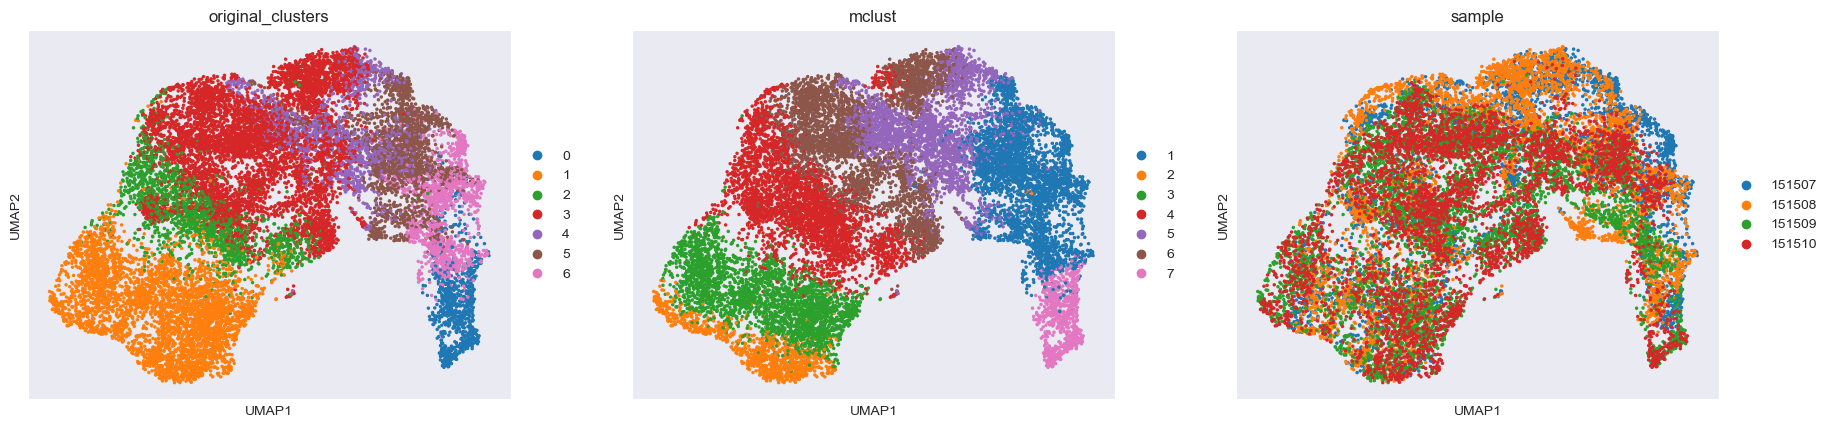

In [10]:
sc.pp.neighbors(adata, use_rep='X_cellcharter', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['original_clusters', 'mclust', 'sample'], show=True, size=25, save=False)

In [11]:
from sklearn.metrics import adjusted_rand_score as ari_score
method = 'mclust'

sub_adata = adata[~pd.isnull(adata.obs['original_clusters'])].copy()
ARI = ari_score(sub_adata.obs['original_clusters'], sub_adata.obs[method])
print(f"ARI:{ARI}")
for name in section_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['sample'] == name]
    ARI = ari_score(sub_adata_tmp.obs['original_clusters'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI:{ARI}")

ARI:0.4773906803798925
151507 ARI:0.47777865445908135
151508 ARI:0.4837972995247836
151509 ARI:0.4913454834083694
151510 ARI:0.47880150310126507


In [12]:
from STG3Net.Metrics import compute_ARI, compute_NMI, compute_HOM, compute_COM, compute_PAS, compute_CHAOS
import pandas as pd
import harmonypy as hm

def compute_metrics(adata, true_label_key, pred_label_key):
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'original_clusters', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in section_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['sample'] == name]
    if sub_adata_tmp.shape[0] > 0:
        metrics = compute_metrics(sub_adata_tmp, 'original_clusters', 'mclust')
        print(f"\n切片 {name}:")
        for metric_name, value in metrics.items():
            print(f"{metric_name}: {value}")
    else:
        print(f"\n切片 {name}: 没有数据可供计算指标。")

整个数据集的指标:
ARI: 0.4773906803798925
NMI: 0.6495043454114283
HOM: 0.6671259681503638
COM: 0.6327896892455334
CHAOS: 0.028498630946630518
PAS: 0.7808729496802891

每个切片的指标:

切片 151507:
ARI: 0.47777865445908135
NMI: 0.6688829659461217
HOM: 0.663267718197303
COM: 0.6745941032679216
CHAOS: 0.056303147489190464
PAS: 0.026770907367922293

切片 151508:
ARI: 0.4837972995247836
NMI: 0.6805482179899315
HOM: 0.6919087491603592
COM: 0.6695547202506059
CHAOS: 0.055154378050530854
PAS: 0.023282355626569277

切片 151509:
ARI: 0.4913454834083694
NMI: 0.6653037814006001
HOM: 0.7058349471175095
COM: 0.6291746788699007
CHAOS: 0.05366492640835669
PAS: 0.02109440267335004

切片 151510:
ARI: 0.47880150310126507
NMI: 0.6517876082718196
HOM: 0.6902567698087043
COM: 0.6173799912078162
CHAOS: 0.055654204765482475
PAS: 0.018933623503808488


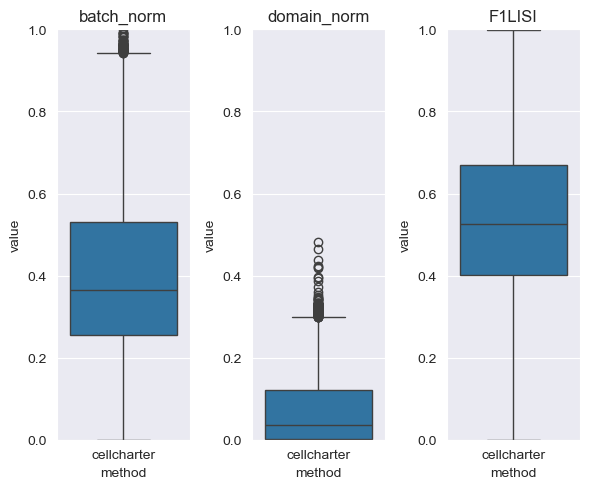

In [13]:
import seaborn as sns

def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'X_cellcharter', 'sample', 'original_clusters')

df_batch_norm = pd.DataFrame({
    'method': 'cellcharter',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'cellcharter',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'cellcharter',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

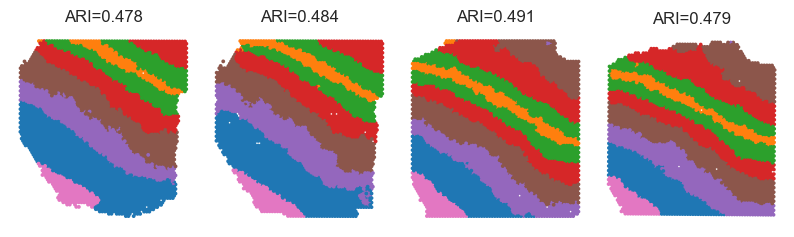

In [14]:
Batch_list = []
for section_id in section_list:
    Batch_list.append(sub_adata[sub_adata.obs['sample'] == section_id])

spot_size = 200
title_size = 12
ARI_list = []
for bb in range(len(section_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['original_clusters'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(section_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [15]:
file_name = 'cellcharter_Donor1.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'

sub_adata.write(file_path)

In [16]:
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_list = ['151669','151670','151671','151672']

adata_list = {}

for section_id in section_list:
    input_dir = os.path.join('C:\Code\Data\DLPFC')
    temp_adata = load_DLPFC(root_dir=input_dir, section_id=section_id)
    temp_adata.var_names_make_unique()

    temp_adata = temp_adata[:, [c for c in temp_adata.var_names if 'NegPrb' not in c]].copy()
    temp_adata.obs_names = [x + '_' + section_id for x in temp_adata.obs_names]
    temp_adata.obs['sample'] = section_id
    temp_adata.obs['sample'] = temp_adata.obs['sample'].astype('category')
    adata_list[section_id] = temp_adata.copy()

adata = ad.concat(adata_list, axis=0, merge='same', pairwise=True, index_unique='_')

adata.layers['count'] = adata.X.toarray()

sc.pp.filter_genes(adata, min_cells=50)
sc.pp.filter_genes(adata, min_counts=10)
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", layer='count', n_top_genes=2000)

scvi.model.SCVI.setup_anndata(
    adata,
    layer="count",
    batch_key='sample',
)

model = scvi.model.SCVI(adata)

model.train(early_stopping=True, enable_progress_bar=True)

adata.obsm['X_scVI'] = model.get_latent_representation(adata).astype(np.float32)

sq.gr.spatial_neighbors(adata, library_key='sample', coord_type='generic', delaunay=True, spatial_key='spatial', percentile=99)

cc.gr.aggregate_neighbors(adata, n_layers=3, use_rep='X_scVI', out_key='X_cellcharter', sample_key='sample')

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 45 records. Best score: 5185.800. Signaling Trainer to stop.


  0%|          | 0/4 [00:00<?, ?it/s]

In [17]:
num_cluster = 5 if section_list == ['151669','151670','151671','151672'] else 7
mclust_R(adata, num_cluster=num_cluster, used_obsm='X_cellcharter')

fitting ...
  |======================================================================| 100%


AnnData object with n_obs × n_vars = 15101 × 15515
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters', 'sample', '_scvi_batch', '_scvi_labels', 'mclust'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', '_scvi_uuid', '_scvi_manager_uuid', 'spatial_neighbors'
    obsm: 'spatial', 'X_scVI', 'X_cellcharter'
    layers: 'count'
    obsp: 'spatial_connectivities', 'spatial_distances'

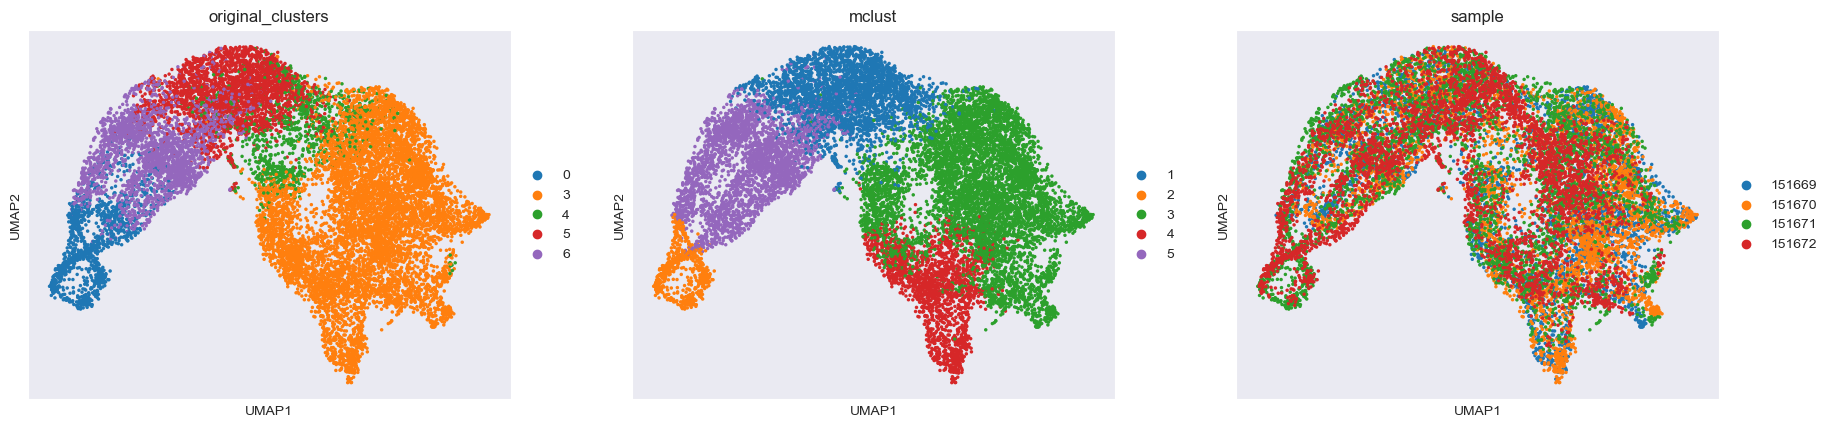

In [18]:
sc.pp.neighbors(adata, use_rep='X_cellcharter', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['original_clusters', 'mclust', 'sample'], show=True, size=25, save=False)

In [19]:
sub_adata = adata[~pd.isnull(adata.obs['original_clusters'])]

def compute_metrics(adata, true_label_key, pred_label_key):
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'original_clusters', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in section_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['sample'] == name]
    if sub_adata_tmp.shape[0] > 0:
        metrics = compute_metrics(sub_adata_tmp, 'original_clusters', 'mclust')
        print(f"\n切片 {name}:")
        for metric_name, value in metrics.items():
            print(f"{metric_name}: {value}")
    else:
        print(f"\n切片 {name}: 没有数据可供计算指标。")

整个数据集的指标:
ARI: 0.5755556386750178
NMI: 0.6489489100358597
HOM: 0.6657716424568985
COM: 0.6329553796607958
CHAOS: 0.020789639525102308
PAS: 0.21627706774385802

每个切片的指标:

切片 151669:
ARI: 0.5015652862289158
NMI: 0.6150699739210782
HOM: 0.6238601259540141
COM: 0.6065240856637246
CHAOS: 0.061194409407293225
PAS: 0.015676567656765675

切片 151670:
ARI: 0.5381206846268977
NMI: 0.6301270201295841
HOM: 0.6486967025958195
COM: 0.6125909072080359
CHAOS: 0.06046475541775078
PAS: 0.010907003444316877

切片 151671:
ARI: 0.6128275176748497
NMI: 0.6853253430195781
HOM: 0.71088755944106
COM: 0.661537658765245
CHAOS: 0.05776711261013393
PAS: 0.013926215489860738

切片 151672:
ARI: 0.6485997380221195
NMI: 0.7004032997880614
HOM: 0.698719029627502
COM: 0.7020957094737599
CHAOS: 0.059531472377652814
PAS: 0.0102880658436214


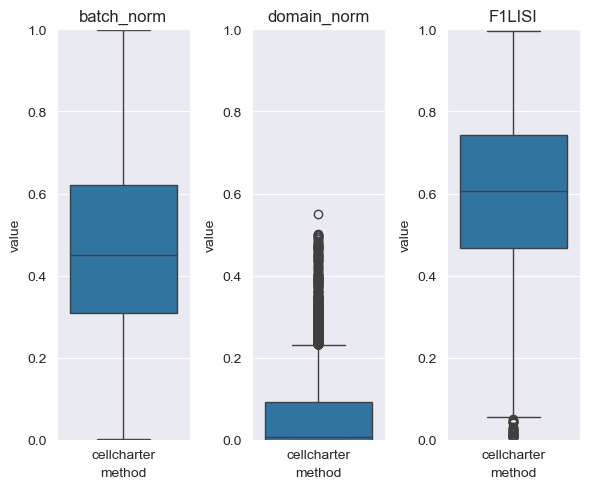

In [20]:
def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'X_cellcharter', 'sample', 'original_clusters')

df_batch_norm = pd.DataFrame({
    'method': 'cellcharter',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'cellcharter',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'cellcharter',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

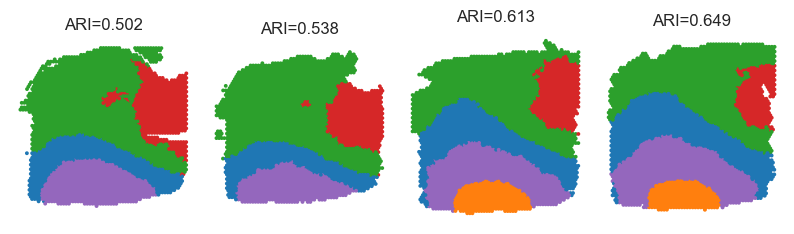

In [21]:
Batch_list = []
for section_id in section_list:
    Batch_list.append(sub_adata[sub_adata.obs['sample'] == section_id])

spot_size = 200
title_size = 12
ARI_list = []
for bb in range(len(section_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['original_clusters'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(section_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [22]:
file_name = 'cellcharter_Donor2.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'

sub_adata.write(file_path)

In [23]:
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_list = ['151673', '151674', '151675', '151676']

adata_list = {}

for section_id in section_list:
    input_dir = os.path.join('C:\Code\Data\DLPFC')
    temp_adata = load_DLPFC(root_dir=input_dir, section_id=section_id)
    temp_adata.var_names_make_unique()

    temp_adata = temp_adata[:, [c for c in temp_adata.var_names if 'NegPrb' not in c]].copy()
    temp_adata.obs_names = [x + '_' + section_id for x in temp_adata.obs_names]
    temp_adata.obs['sample'] = section_id
    temp_adata.obs['sample'] = temp_adata.obs['sample'].astype('category')
    adata_list[section_id] = temp_adata.copy()

adata = ad.concat(adata_list, axis=0, merge='same', pairwise=True, index_unique='_')

adata.layers['count'] = adata.X.toarray()

sc.pp.filter_genes(adata, min_cells=50)
sc.pp.filter_genes(adata, min_counts=10)
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", layer='count', n_top_genes=2000)

scvi.model.SCVI.setup_anndata(
    adata,
    layer="count",
    batch_key='sample',
)

model = scvi.model.SCVI(adata)

model.train(early_stopping=True, enable_progress_bar=True)

adata.obsm['X_scVI'] = model.get_latent_representation(adata).astype(np.float32)

sq.gr.spatial_neighbors(adata, library_key='sample', coord_type='generic', delaunay=True, spatial_key='spatial', percentile=99)

cc.gr.aggregate_neighbors(adata, n_layers=3, use_rep='X_scVI', out_key='X_cellcharter', sample_key='sample')

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 45 records. Best score: 6061.458. Signaling Trainer to stop.


  0%|          | 0/4 [00:00<?, ?it/s]

In [24]:
num_cluster = 5 if section_list == ['151669','151670','151671','151672'] else 7
mclust_R(adata, num_cluster=num_cluster, used_obsm='X_cellcharter')

fitting ...
  |======================================================================| 100%


AnnData object with n_obs × n_vars = 14243 × 16076
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters', 'sample', '_scvi_batch', '_scvi_labels', 'mclust'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', '_scvi_uuid', '_scvi_manager_uuid', 'spatial_neighbors'
    obsm: 'spatial', 'X_scVI', 'X_cellcharter'
    layers: 'count'
    obsp: 'spatial_connectivities', 'spatial_distances'

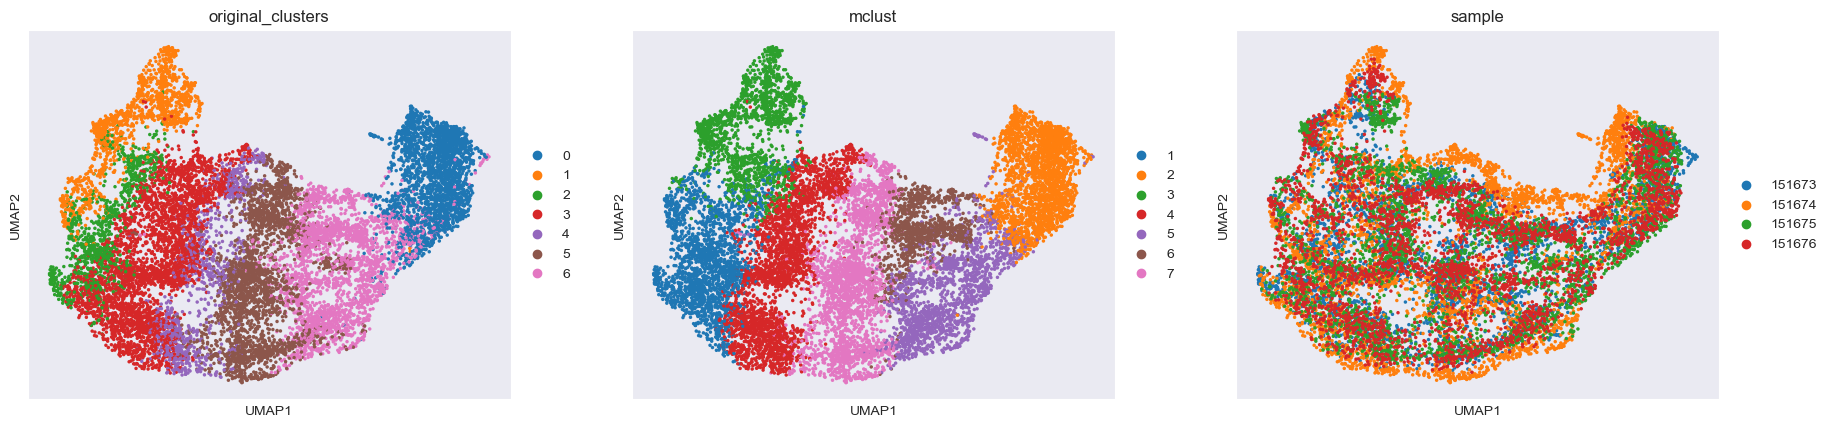

In [25]:
sc.pp.neighbors(adata, use_rep='X_cellcharter', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['original_clusters', 'mclust', 'sample'], show=True, size=25, save=False)

In [26]:
sub_adata = adata[~pd.isnull(adata.obs['original_clusters'])].copy()

def compute_metrics(adata, true_label_key, pred_label_key):
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'original_clusters', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in section_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['sample'] == name]
    metrics = compute_metrics(sub_adata_tmp, 'original_clusters', 'mclust')
    print(f"\n切片 {name}:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value}")

整个数据集的指标:
ARI: 0.563680491583745
NMI: 0.670392240528355
HOM: 0.6804264086543326
COM: 0.6606497169462264
CHAOS: 0.017773689863315206
PAS: 0.201432282524749

每个切片的指标:

切片 151673:
ARI: 0.5361106152601114
NMI: 0.6675813448258917
HOM: 0.682254453506518
COM: 0.6535260912281603
CHAOS: 0.06072822223743382
PAS: 0.024093049016892826

切片 151674:
ARI: 0.5935991892787186
NMI: 0.7109971910304731
HOM: 0.7219336991295684
COM: 0.700387090549594
CHAOS: 0.05993436697939259
PAS: 0.02200825309491059

切片 151675:
ARI: 0.5858860317251192
NMI: 0.690488082193026
HOM: 0.6960209334655316
COM: 0.6850425013304865
CHAOS: 0.060438362154975805
PAS: 0.02075154234436343

切片 151676:
ARI: 0.559671252288645
NMI: 0.6684083788647952
HOM: 0.6773481335286313
COM: 0.6597015270827514
CHAOS: 0.062399843396179454
PAS: 0.025357038764208684


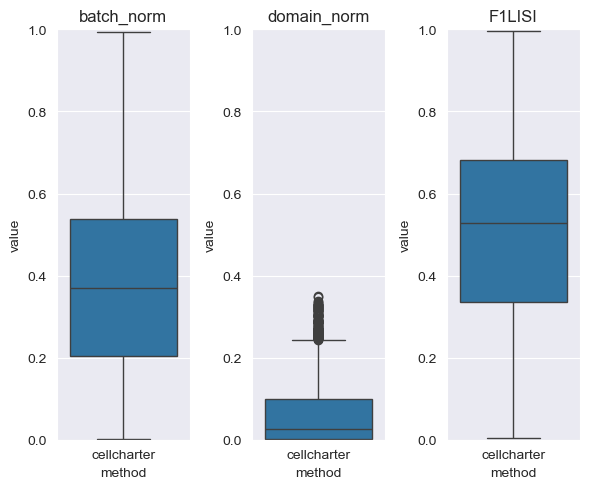

In [27]:
def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'X_cellcharter', 'sample', 'original_clusters')

df_batch_norm = pd.DataFrame({
    'method': 'cellcharter',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'cellcharter',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'cellcharter',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

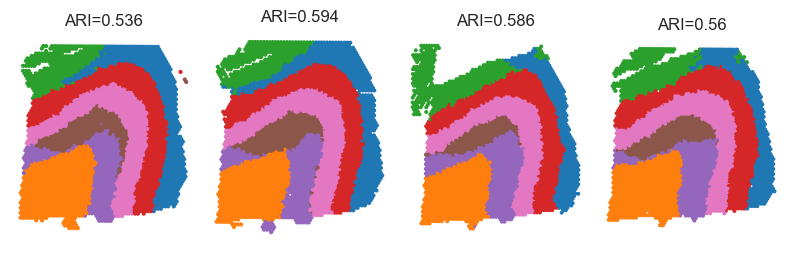

In [28]:
Batch_list = []
for section_id in section_list:
    Batch_list.append(sub_adata[sub_adata.obs['sample'] == section_id])

spot_size = 200
title_size = 12
ARI_list = []
for bb in range(len(section_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['original_clusters'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(section_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [29]:
file_name = 'cellcharter_Donor3.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'

sub_adata.write(file_path)